In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Day 13 libraries imported successfully.")

Day 13 libraries imported successfully.


In [2]:
day13_input_path = Path(
    "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"
)

if not day13_input_path.exists():
    raise FileNotFoundError(
        f"Input dataset not found: "
        f"{day13_input_path.resolve()}"
    )

df_day13_source = pd.read_csv(
    day13_input_path,
    encoding="cp1252",
    low_memory=False
)

df_day13 = df_day13_source.copy()

print("Day 13 source dataset loaded successfully.")
print("Dataset shape:", df_day13.shape)

display(df_day13.head())

Day 13 source dataset loaded successfully.
Dataset shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


## Dataset Overview & Validation

In [3]:
required_columns = [
    "Product Name",
    "Category Name",
    "Category Id",
    "Department Name",
    "Product Price",
    "Order Item Product Price",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Profit_Margin",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Delivery Status",
    "Delay_Severity",
    "Late_delivery_risk"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df_day13.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required product analysis columns are available.")

print("Total rows:", len(df_day13))
print("Total columns:", len(df_day13.columns))

print("Duplicate rows:", df_day13.duplicated().sum())

display(
    df_day13[required_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
    .sort_values("Missing_Values", ascending=False)
)   

All required product analysis columns are available.
Total rows: 180519
Total columns: 56
Duplicate rows: 0


,Missing_Values
Product Name,0
Category Name,0
Category Id,0
Department Name,0
Product Price,0
Order Item Product Price,0
Order Item Quantity,0
Sales,0
Order Item Total,0
Order Profit Per Order,0


### Validate Product & Category Information

In [5]:
product_category_validation = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Products",
        "Unique Categories",
        "Unique Departments",
        "Missing Product Names",
        "Missing Category Names",
        "Missing Department Names",
        "Missing Category IDs"
    ],

    "Value": [
        len(df_day13),
        df_day13["Product Name"].nunique(),
        df_day13["Category Name"].nunique(),
        df_day13["Department Name"].nunique(),
        df_day13["Product Name"].isna().sum(),
        df_day13["Category Name"].isna().sum(),
        df_day13["Department Name"].isna().sum(),
        df_day13["Category Id"].isna().sum()
    ]
})

display(product_category_validation)

,Metric,Value
0,Total Records,180519
1,Unique Products,118
2,Unique Categories,50
3,Unique Departments,11
4,Missing Product Names,0
5,Missing Category Names,0
6,Missing Department Names,0
7,Missing Category IDs,0


## Prepare the Product Analysis Columns

In [6]:
numeric_columns = [
    "Category Id",
    "Product Price",
    "Order Item Product Price",
    "Order Item Quantity",
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Profit_Margin",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Late_delivery_risk"
]

for col in numeric_columns:
    df_day13[col] = pd.to_numeric(
        df_day13[col],
        errors="coerce"
    )

print("Numeric columns converted successfully.")

display(
    df_day13[numeric_columns]
    .describe()
    .round(2)
)

Numeric columns converted successfully.


,Category Id,Product Price,Order Item Product Price,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Item Profit Ratio,Profit_Margin,Is_Delayed,Shipping_Delay_Days,Late_delivery_risk
count,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00,180519.00
mean,31.85,141.23,141.23,2.13,203.77,183.11,21.97,0.12,0.11,0.57,0.57,0.55
std,15.64,139.73,139.73,1.45,132.27,120.04,104.43,0.47,0.42,0.49,1.49,0.50
min,2.00,9.99,9.99,1.00,9.99,7.49,-4274.98,-2.75,-2.75,0.00,-2.00,0.00
25%,18.00,50.00,50.00,1.00,119.98,104.38,7.00,0.08,0.06,0.00,0.00,0.00
50%,29.00,59.99,59.99,1.00,199.92,163.99,31.52,0.27,0.24,1.00,1.00,1.00
75%,45.00,199.99,199.99,3.00,299.95,247.40,64.80,0.36,0.34,1.00,1.00,1.00
max,76.00,1999.99,1999.99,5.00,1999.99,1939.99,911.80,0.50,0.50,1.00,4.00,1.00


### Checking missing values after conversions

In [7]:
numeric_missing_check = (
    df_day13[numeric_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
    .sort_values("Missing_Values", ascending=False)
)

display(numeric_missing_check)

,Missing_Values
Category Id,0
Product Price,0
Order Item Product Price,0
Order Item Quantity,0
Sales,0
Order Item Total,0
Order Profit Per Order,0
Order Item Profit Ratio,0
Profit_Margin,0
Is_Delayed,0


## Product Category Performance Analysis

In [8]:
category_performance = (
    df_day13
    .dropna(subset=["Category Name"])
    .groupby("Category Name")
    .agg(
        Total_Records=(
            "Category Name",
            "size"
        ),

        Unique_Products=(
            "Product Name",
            "nunique"
        ),

        Total_Quantity_Sold=(
            "Order Item Quantity",
            "sum"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Average_Sales_Per_Record=(
            "Sales",
            "mean"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),

        Average_Product_Price=(
            "Product Price",
            "mean"
        ),

        Average_Profit_Margin=(
            "Profit_Margin",
            "mean"
        ),

        Delayed_Records=(
            "Is_Delayed",
            "sum"
        ),

        Average_Shipping_Delay_Days=(
            "Shipping_Delay_Days",
            "mean"
        )
    )
    .reset_index()
)

category_performance["Delay_Rate_%"] = (
    category_performance["Delayed_Records"]
    / category_performance["Total_Records"]
    * 100
)

category_performance["Sales_Share_%"] = (
    category_performance["Total_Sales"]
    / category_performance["Total_Sales"].sum()
    * 100
)

category_performance["Profit_Share_%"] = (
    category_performance["Total_Order_Profit"]
    / category_performance["Total_Order_Profit"].sum()
    * 100
)

category_performance = category_performance.sort_values(
    "Total_Sales",
    ascending=False
)

display(
    category_performance.round(2)
)

,Category Name,Total_Records,Unique_Products,Total_Quantity_Sold,Total_Sales,Average_Sales_Per_Record,Total_Order_Profit,Average_Order_Profit,Average_Product_Price,Average_Profit_Margin,Delayed_Records,Average_Shipping_Delay_Days,Delay_Rate_%,Sales_Share_%,Profit_Share_%
18,Fishing,17325,1,17325,6929653.50,399.98,756220.76,43.65,399.98,0.11,9930,0.56,57.32,18.84,19.06
12,Cleats,24551,2,73734,4431942.66,180.52,494636.92,20.15,60.34,0.11,14076,0.58,57.33,12.05,12.47
9,Camping & Hiking,13729,1,13729,4118425.42,299.98,427455.57,31.14,299.98,0.10,7812,0.55,56.90,11.20,10.78
10,Cardio Equipment,12487,2,37587,3694843.20,295.90,383011.10,30.67,98.21,0.11,7110,0.55,56.94,10.04,9.66
47,Women's Apparel,21035,1,62956,3147800.00,149.65,350421.03,16.66,50.00,0.11,12017,0.56,57.13,8.56,8.83
46,Water Sports,15540,2,15540,3113844.60,200.38,325146.96,20.92,200.38,0.10,8891,0.57,57.21,8.47,8.20
34,Men's Footwear,22246,1,22246,2891757.54,129.99,311902.82,14.02,129.99,0.11,12664,0.56,56.93,7.86,7.86
30,Indoor/Outdoor Games,19298,1,57803,2888993.94,149.70,318451.43,16.50,49.98,0.11,11043,0.56,57.22,7.85,8.03
38,Shop By Sport,10984,3,32726,1309522.02,119.22,129813.96,11.82,40.63,0.10,6328,0.58,57.61,3.56,3.27
13,Computers,442,1,442,663000.00,1500.00,69656.81,157.59,1500.00,0.11,233,0.45,52.71,1.80,1.76


## Indiviual Product Performance Analysis

In [9]:
product_performance = (
    df_day13
    .dropna(subset=["Product Name"])
    .groupby("Product Name")
    .agg(
        Total_Records=(
            "Product Name",
            "size"
        ),

        Categories=(
            "Category Name",
            "nunique"
        ),

        Total_Quantity_Sold=(
            "Order Item Quantity",
            "sum"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Average_Sales_Per_Record=(
            "Sales",
            "mean"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),

        Average_Product_Price=(
            "Product Price",
            "mean"
        ),

        Average_Profit_Margin=(
            "Profit_Margin",
            "mean"
        ),

        Delayed_Records=(
            "Is_Delayed",
            "sum"
        ),

        Average_Shipping_Delay_Days=(
            "Shipping_Delay_Days",
            "mean"
        )
    )
    .reset_index()
)

product_performance["Delay_Rate_%"] = (
    product_performance["Delayed_Records"]
    / product_performance["Total_Records"]
    * 100
)

product_performance["Sales_Share_%"] = (
    product_performance["Total_Sales"]
    / product_performance["Total_Sales"].sum()
    * 100
)

product_performance["Profit_Share_%"] = (
    product_performance["Total_Order_Profit"]
    / product_performance["Total_Order_Profit"].sum()
    * 100
)

product_performance = product_performance.sort_values(
    "Total_Sales",
    ascending=False
)

display(
    product_performance.head(20).round(2)
)

,Product Name,Total_Records,Categories,Total_Quantity_Sold,Total_Sales,Average_Sales_Per_Record,Total_Order_Profit,Average_Order_Profit,Average_Product_Price,Average_Profit_Margin,Delayed_Records,Average_Shipping_Delay_Days,Delay_Rate_%,Sales_Share_%,Profit_Share_%
24,Field & Stream Sportsman 16 Gun Fire Safe,17325,1,17325,6929653.50,399.98,756220.76,43.65,399.98,0.11,9930,0.56,57.32,18.84,19.06
71,Perfect Fitness Perfect Rip Deck,24515,1,73698,4421143.02,180.34,493828.30,20.14,59.99,0.11,14053,0.58,57.32,12.02,12.45
21,Diamondback Women's Serene Classic Comfort Bi,13729,1,13729,4118425.42,299.98,427455.57,31.14,299.98,0.10,7812,0.55,56.90,11.20,10.78
61,Nike Men's Free 5.0+ Running Shoe,12169,1,36680,3667633.20,301.39,379915.82,31.22,99.99,0.11,6925,0.55,56.91,9.97,9.58
59,Nike Men's Dri-FIT Victory Golf Polo,21035,1,62956,3147800.00,149.65,350421.03,16.66,50.00,0.11,12017,0.56,57.13,8.56,8.83
70,Pelican Sunstream 100 Kayak,15500,1,15500,3099845.00,199.99,324076.37,20.91,199.99,0.10,8866,0.57,57.20,8.43,8.17
56,Nike Men's CJ Elite 2 TD Football Cleat,22246,1,22246,2891757.54,129.99,311902.82,14.02,129.99,0.11,12664,0.56,56.93,7.86,7.86
67,O'Brien Men's Neoprene Life Vest,19298,1,57803,2888993.94,149.70,318451.43,16.50,49.98,0.11,11043,0.56,57.22,7.85,8.03
102,Under Armour Girls' Toddler Spine Surge Runni,10617,1,31735,1269082.65,119.53,126278.51,11.89,39.99,0.10,6126,0.58,57.70,3.45,3.18
18,Dell Laptop,442,1,442,663000.00,1500.00,69656.81,157.59,1500.00,0.11,233,0.45,52.71,1.80,1.76


## Department-Level Product Analysis

In [10]:
department_performance = (
    df_day13
    .dropna(subset=["Department Name"])
    .groupby("Department Name")
    .agg(
        Total_Records=(
            "Department Name",
            "size"
        ),

        Unique_Products=(
            "Product Name",
            "nunique"
        ),

        Unique_Categories=(
            "Category Name",
            "nunique"
        ),

        Total_Quantity_Sold=(
            "Order Item Quantity",
            "sum"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),

        Average_Profit_Margin=(
            "Profit_Margin",
            "mean"
        ),

        Delayed_Records=(
            "Is_Delayed",
            "sum"
        ),

        Average_Shipping_Delay_Days=(
            "Shipping_Delay_Days",
            "mean"
        )
    )
    .reset_index()
)

department_performance["Delay_Rate_%"] = (
    department_performance["Delayed_Records"]
    / department_performance["Total_Records"]
    * 100
)

department_performance["Sales_Share_%"] = (
    department_performance["Total_Sales"]
    / department_performance["Total_Sales"].sum()
    * 100
)

department_performance = department_performance.sort_values(
    "Total_Sales",
    ascending=False
)

display(
    department_performance.round(2)
)

,Department Name,Total_Records,Unique_Products,Unique_Categories,Total_Quantity_Sold,Total_Sales,Total_Order_Profit,Average_Profit_Margin,Delayed_Records,Average_Shipping_Delay_Days,Delay_Rate_%,Sales_Share_%
3,Fan Shop,66861,9,6,106165,17113870.54,1834155.43,0.11,38242,0.56,57.20,46.52
0,Apparel,48998,8,7,98181,7976255.08,881882.93,0.11,28009,0.57,57.16,21.68
6,Golf,33220,8,3,99297,4609028.22,497523.56,0.11,19049,0.57,57.34,12.53
5,Footwear,14525,15,6,43400,4006498.77,410222.50,0.11,8312,0.56,57.23,10.89
8,Outdoors,9686,53,12,26059,1253351.44,145251.46,0.11,5604,0.57,57.86,3.41
10,Technology,1465,3,3,1465,1039598.96,113170.01,0.11,855,0.59,58.36,2.83
4,Fitness,2479,15,7,6227,397050.89,46538.06,0.12,1433,0.58,57.81,1.08
2,Discs Shop,2026,4,4,2026,228887.73,24193.12,0.10,1149,0.55,56.71,0.62
7,Health and Beauty,362,1,1,362,106080.48,9493.63,0.09,212,0.53,58.56,0.29
9,Pet Shop,492,1,1,492,41524.80,3589.26,0.09,302,0.71,61.38,0.11


## Product and Category Delay Analysis

In [11]:
category_delay_severity = (
    df_day13
    .dropna(
        subset=[
            "Category Name",
            "Delay_Severity"
        ]
    )
    .groupby(
        ["Category Name", "Delay_Severity"]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(category_delay_severity)

Delay_Severity,Category Name,Major Delay,Minor Delay,On Time / Early
0,Accessories,420,633,727
1,As Seen on TV!,20,20,28
2,Baby,38,75,94
3,Baseball & Softball,153,204,275
4,Basketball,15,25,27
5,Books,84,149,172
6,Boxing & MMA,103,148,172
7,CDs,54,93,124
8,Cameras,128,239,225
9,Camping & Hiking,3218,4594,5917


### Product with the highest delay rates

In [12]:
product_delay_analysis = (
    df_day13
    .dropna(subset=["Product Name"])
    .groupby("Product Name")
    .agg(
        Total_Records=(
            "Product Name",
            "size"
        ),

        Delayed_Records=(
            "Is_Delayed",
            "sum"
        ),

        Average_Shipping_Delay_Days=(
            "Shipping_Delay_Days",
            "mean"
        ),

        Maximum_Shipping_Delay_Days=(
            "Shipping_Delay_Days",
            "max"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        )
    )
    .reset_index()
)

product_delay_analysis["Delay_Rate_%"] = (
    product_delay_analysis["Delayed_Records"]
    / product_delay_analysis["Total_Records"]
    * 100
)

product_delay_analysis = product_delay_analysis.sort_values(
    [
        "Delay_Rate_%",
        "Total_Records"
    ],
    ascending=[False, False]
)

display(
    product_delay_analysis.head(20).round(2)
)

,Product Name,Total_Records,Delayed_Records,Average_Shipping_Delay_Days,Maximum_Shipping_Delay_Days,Total_Sales,Total_Order_Profit,Delay_Rate_%
76,SOLE E25 Elliptical,10,7,1.00,3,9999.90,-169.56,70.00
68,Ogio Race Golf Shoes,61,42,0.77,4,10369.39,1810.07,68.85
29,Garmin Approach S4 Golf GPS Watch,36,24,0.89,4,10799.64,1208.90,66.67
36,GoPro HERO3+ Black Edition Camera,32,21,0.59,4,12799.68,245.63,65.62
19,Diamondback Boys' Insight 24 Performance Hybr,29,19,0.72,4,8699.71,1730.81,65.52
89,Team Golf St. Louis Cardinals Putter Grip,313,204,0.73,4,23940.42,2815.12,65.18
98,Titleist Small Wheeled Travel Cover,54,35,0.76,4,13499.46,1011.65,64.81
93,Titleist Club Glove Travel Cover,34,22,0.91,4,10199.66,1312.27,64.71
100,Total Gym 1400,36,23,0.64,3,10799.64,808.62,63.89
40,Hirzl Women's Soffft Flex Golf Glove,298,190,0.68,4,15993.11,1444.25,63.76


## Negative-Profit Product Analysis

In [13]:
negative_profit_category = (
    df_day13
    .dropna(subset=["Category Name"])
    .assign(
        Is_Negative_Profit=lambda x: (
            x["Order Profit Per Order"] < 0
        )
    )
    .groupby("Category Name")
    .agg(
        Total_Records=(
            "Category Name",
            "size"
        ),

        Negative_Profit_Records=(
            "Is_Negative_Profit",
            "sum"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        )
    )
    .reset_index()
)

negative_profit_category["Negative_Profit_Rate_%"] = (
    negative_profit_category["Negative_Profit_Records"]
    / negative_profit_category["Total_Records"]
    * 100
)

negative_profit_category = negative_profit_category.sort_values(
    [
        "Negative_Profit_Rate_%",
        "Total_Records"
    ],
    ascending=[False, False]
)

display(
    negative_profit_category.round(2)
)

,Category Name,Total_Records,Negative_Profit_Records,Total_Sales,Total_Order_Profit,Negative_Profit_Rate_%
33,Men's Clothing,208,50,43856.80,2006.04,24.04
27,Health and Beauty,362,85,106080.48,9493.63,23.48
45,Video Games,838,181,33310.50,2717.52,21.60
26,Golf Shoes,524,111,107998.00,12406.07,21.18
37,Pet Supplies,492,104,41524.80,3589.26,21.14
16,DVDs,483,102,79395.54,6655.43,21.12
1,As Seen on TV!,68,14,20597.94,714.43,20.59
31,Kids' Golf Clubs,384,77,98797.58,9045.84,20.05
22,Golf Apparel,441,88,34969.75,3496.31,19.95
15,Crafts,484,96,223356.32,25531.17,19.83


### Negative-profit analysis by product

In [14]:
negative_profit_product = (
    df_day13
    .dropna(subset=["Product Name"])
    .assign(
        Is_Negative_Profit=lambda x: (
            x["Order Profit Per Order"] < 0
        )
    )
    .groupby("Product Name")
    .agg(
        Total_Records=(
            "Product Name",
            "size"
        ),

        Negative_Profit_Records=(
            "Is_Negative_Profit",
            "sum"
        ),

        Total_Sales=(
            "Sales",
            "sum"
        ),

        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        )
    )
    .reset_index()
)

negative_profit_product["Negative_Profit_Rate_%"] = (
    negative_profit_product["Negative_Profit_Records"]
    / negative_profit_product["Total_Records"]
    * 100
)

negative_profit_product = negative_profit_product.sort_values(
    [
        "Negative_Profit_Rate_%",
        "Total_Records"
    ],
    ascending=[False, False]
)

display(
    negative_profit_product.head(20).round(2)
)

,Product Name,Total_Records,Negative_Profit_Records,Total_Sales,Total_Order_Profit,Negative_Profit_Rate_%
76,SOLE E25 Elliptical,10,3,9999.90,-169.56,30.00
80,Stiga Master Series ST3100 Competition Indoor,27,8,8909.73,479.28,29.63
30,Garmin Forerunner 910XT GPS Watch,35,10,13999.65,391.13,28.57
9,Bushnell Pro X7 Jolt Slope Rangefinder,11,3,6599.89,-255.95,27.27
12,Cleveland Golf Collegiate My Custom Wedge 588,65,16,13649.35,955.10,24.62
64,Nike Women's Free 5.0 TR FIT PRT 4 Training S,70,17,19567.94,1564.75,24.29
42,LIJA Women's Argyle Golf Polo,66,16,15600.00,1512.43,24.24
48,Men's gala suit,208,50,43856.80,2006.04,24.04
93,Titleist Club Glove Travel Cover,34,8,10199.66,1312.27,23.53
26,First aid kit,362,85,106080.48,9493.63,23.48


## Visualize Product and Category Performance

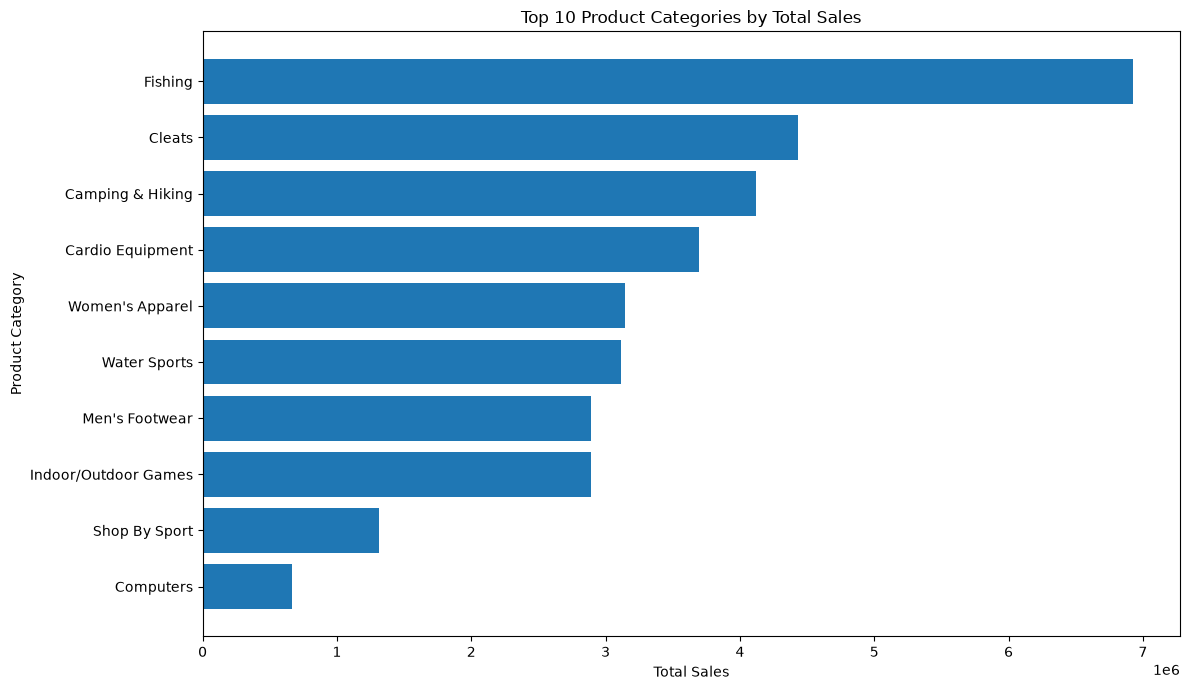

In [15]:
top_10_categories_sales = (
    category_performance
    .nlargest(10, "Total_Sales")
    .sort_values("Total_Sales")
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories_sales["Category Name"],
    top_10_categories_sales["Total_Sales"]
)

plt.title("Top 10 Product Categories by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

### Top 10 Categories by Profit

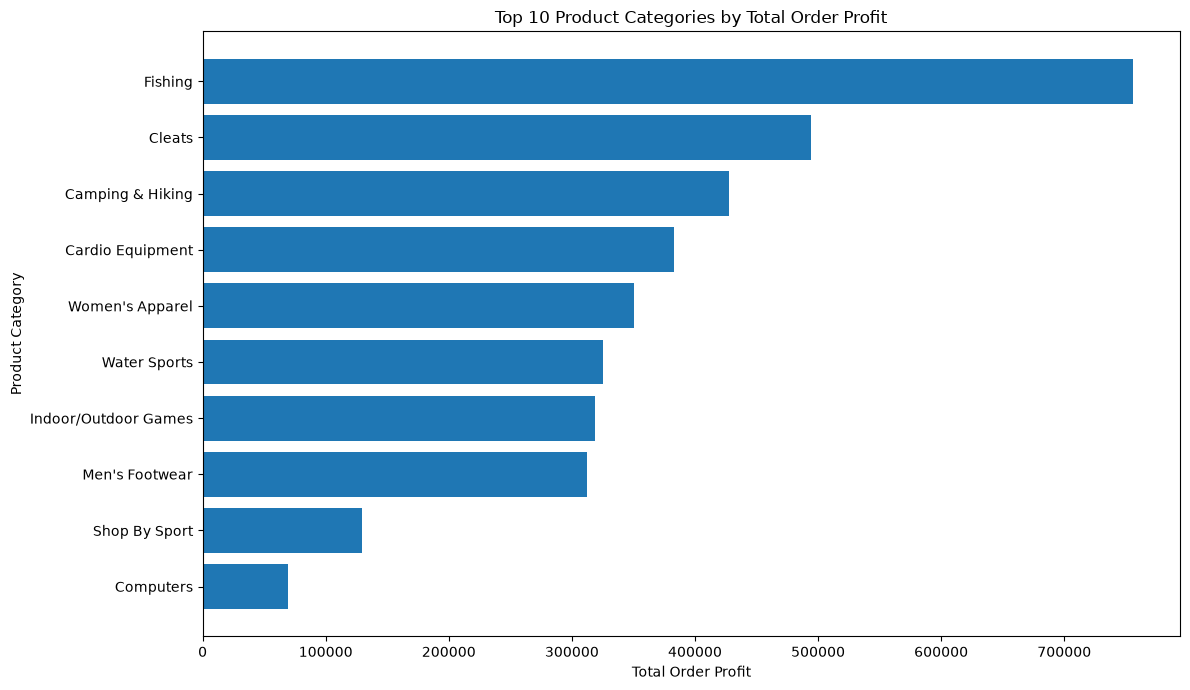

In [16]:
top_10_categories_profit = (
    category_performance
    .nlargest(10, "Total_Order_Profit")
    .sort_values("Total_Order_Profit")
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories_profit["Category Name"],
    top_10_categories_profit["Total_Order_Profit"]
)

plt.title("Top 10 Product Categories by Total Order Profit")
plt.xlabel("Total Order Profit")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

### Top 10 Products by Sales

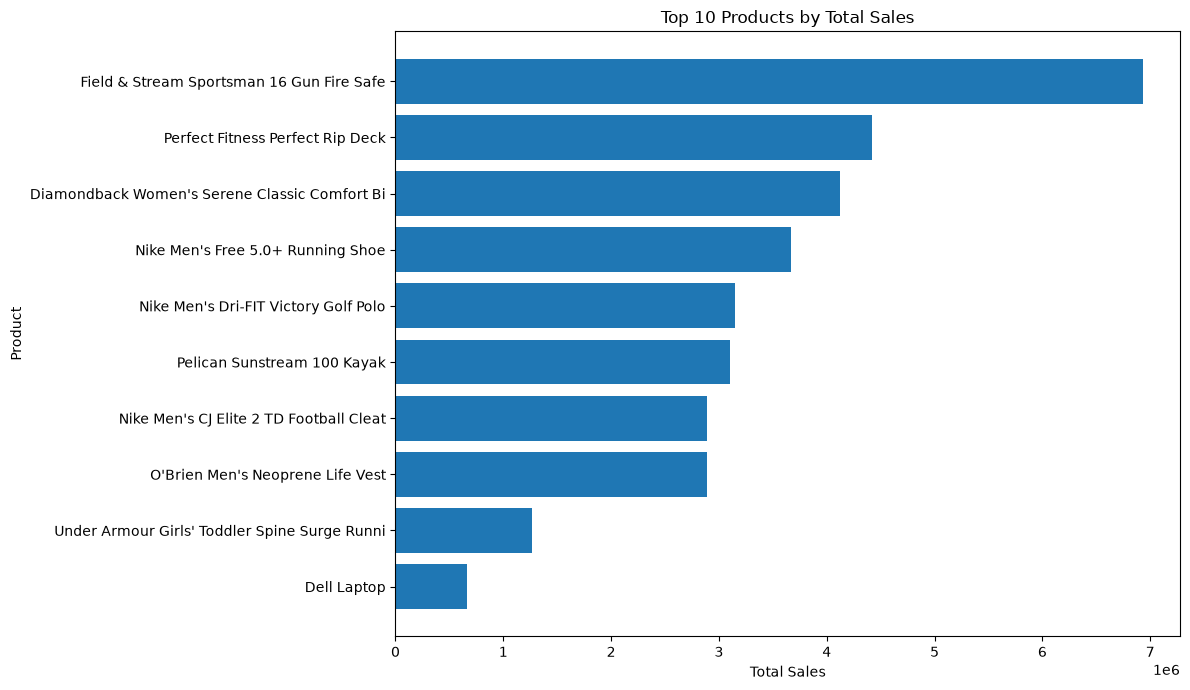

In [18]:
top_10_products_sales = (
    product_performance
    .nlargest(10, "Total_Sales")
    .sort_values("Total_Sales")
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_products_sales["Product Name"],
    top_10_products_sales["Total_Sales"]
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

### Category Delay Rates

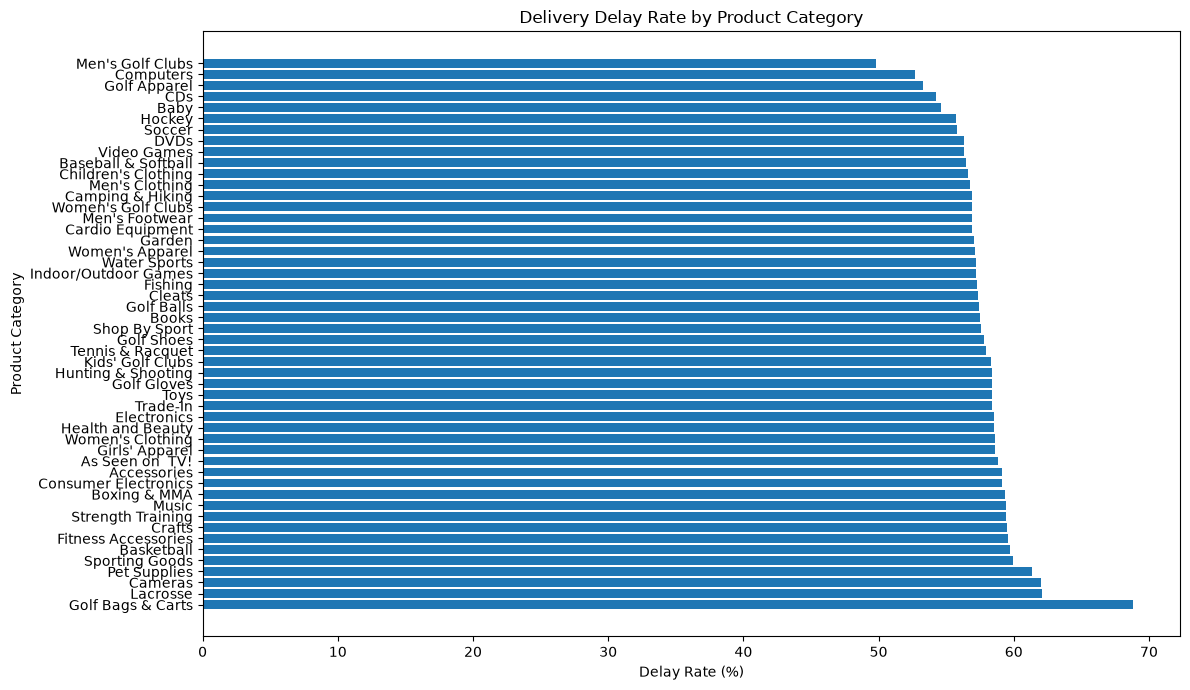

In [19]:
category_delay_chart = (
    category_performance
    .sort_values("Delay_Rate_%", ascending=False)
)

plt.figure(figsize=(12, 7))

plt.barh(
    category_delay_chart["Category Name"],
    category_delay_chart["Delay_Rate_%"]
)

plt.title("Delivery Delay Rate by Product Category")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

## Day 13 KPI Summary 

In [20]:
total_records = len(df_day13)

total_sales = df_day13["Sales"].sum()

total_order_profit = (
    df_day13["Order Profit Per Order"].sum()
)

total_quantity = (
    df_day13["Order Item Quantity"].sum()
)

delayed_records = (
    df_day13["Is_Delayed"].sum()
)

overall_delay_rate = (
    delayed_records / total_records * 100
    if total_records > 0
    else np.nan
)

highest_sales_category = (
    category_performance
    .loc[
        category_performance["Total_Sales"].idxmax(),
        "Category Name"
    ]
    if not category_performance.empty
    else "Unavailable"
)

highest_profit_category = (
    category_performance
    .loc[
        category_performance["Total_Order_Profit"].idxmax(),
        "Category Name"
    ]
    if not category_performance.empty
    else "Unavailable"
)

highest_sales_product = (
    product_performance
    .loc[
        product_performance["Total_Sales"].idxmax(),
        "Product Name"
    ]
    if not product_performance.empty
    else "Unavailable"
)

highest_delay_category = (
    category_performance
    .loc[
        category_performance["Delay_Rate_%"].idxmax(),
        "Category Name"
    ]
    if not category_performance.empty
    else "Unavailable"
)

day13_kpis = pd.DataFrame({
    "Metric": [
        "Total Product Records",
        "Unique Products",
        "Unique Categories",
        "Unique Departments",
        "Total Recorded Quantity",
        "Total Sales",
        "Total Order Profit",
        "Delayed Records",
        "Overall Delay Rate (%)",
        "Highest Sales Category",
        "Highest Profit Category",
        "Highest Sales Product",
        "Highest Delay Rate Category"
    ],

    "Value": [
        total_records,
        df_day13["Product Name"].nunique(),
        df_day13["Category Name"].nunique(),
        df_day13["Department Name"].nunique(),
        total_quantity,
        total_sales,
        total_order_profit,
        delayed_records,
        overall_delay_rate,
        highest_sales_category,
        highest_profit_category,
        highest_sales_product,
        highest_delay_category
    ]
})

display(day13_kpis)

,Metric,Value
0,Total Product Records,180519
1,Unique Products,118
2,Unique Categories,50
3,Unique Departments,11
4,Total Recorded Quantity,384079
5,Total Sales,36784734.31
6,Total Order Profit,3966902.97
7,Delayed Records,103400
8,Overall Delay Rate (%),57.279289
9,Highest Sales Category,Fishing


## Saving Day 13 Anlaytics Reports

In [21]:
day13_output_dir = Path(
    "../data/analysis_data/"
)

if not day13_output_dir.exists():
    raise FileNotFoundError(
        f"Output directory does not exist: "
        f"{day13_output_dir.resolve()}"
    )

day13_outputs = {
    "APL_Day13_Product_Category_KPIs.csv":
        day13_kpis,

    "APL_Day13_Category_Performance.csv":
        category_performance,

    "APL_Day13_Product_Performance.csv":
        product_performance,

    "APL_Day13_Department_Performance.csv":
        department_performance,

    "APL_Day13_Category_Delay_Severity.csv":
        category_delay_severity,

    "APL_Day13_Product_Delay_Analysis.csv":
        product_delay_analysis,

    "APL_Day13_Negative_Profit_Category.csv":
        negative_profit_category,

    "APL_Day13_Negative_Profit_Product.csv":
        negative_profit_product
}

for filename, output_df in day13_outputs.items():

    output_path = day13_output_dir / filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved:", output_path.resolve())

print("All Day 13 analytical outputs saved successfully.")

Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day13_Product_Category_KPIs.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day13_Category_Performance.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day13_Product_Performance.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day13_Department_Performance.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day13_Category_Delay_Severity.csv
Saved: D:\Data Analytics Project\Delivery Performa

## Validate Day 13 Results

In [22]:
category_sales_valid = np.isclose(
    category_performance["Total_Sales"].sum(),
    df_day13.loc[
        df_day13["Category Name"].notna(),
        "Sales"
    ].sum(),
    equal_nan=False
)

product_sales_valid = np.isclose(
    product_performance["Total_Sales"].sum(),
    df_day13.loc[
        df_day13["Product Name"].notna(),
        "Sales"
    ].sum(),
    equal_nan=False
)

category_profit_valid = np.isclose(
    category_performance["Total_Order_Profit"].sum(),
    df_day13.loc[
        df_day13["Category Name"].notna(),
        "Order Profit Per Order"
    ].sum(),
    equal_nan=False
)

product_profit_valid = np.isclose(
    product_performance["Total_Order_Profit"].sum(),
    df_day13.loc[
        df_day13["Product Name"].notna(),
        "Order Profit Per Order"
    ].sum(),
    equal_nan=False
)

negative_profit_valid = (
    negative_profit_category[
        "Negative_Profit_Records"
    ].sum()
    ==
    (
        df_day13["Order Profit Per Order"].lt(0)
        & df_day13["Category Name"].notna()
        & df_day13["Order Profit Per Order"].notna()
    ).sum()
)

category_delay_valid = (
    category_performance["Delayed_Records"].sum()
    ==
    df_day13.loc[
        df_day13["Category Name"].notna(),
        "Is_Delayed"
    ].sum()
)

output_files_exist = all(
    (day13_output_dir / filename).exists()
    for filename in day13_outputs
)

validation_results = {
    "Source Dataset Loaded":
        not df_day13.empty,

    "Required Columns Available":
        len(missing_columns) == 0,

    "Category Performance Not Empty":
        not category_performance.empty,

    "Product Performance Not Empty":
        not product_performance.empty,

    "Department Performance Not Empty":
        not department_performance.empty,

    "Category Sales Reconcile":
        category_sales_valid,

    "Product Sales Reconcile":
        product_sales_valid,

    "Category Profit Reconcile":
        category_profit_valid,

    "Product Profit Reconcile":
        product_profit_valid,

    "Negative Profit Records Reconcile":
        negative_profit_valid,

    "Category Delay Records Reconcile":
        category_delay_valid,

    "All Analytical Output Files Exist":
        output_files_exist
}

day13_validation = pd.DataFrame([
    {
        "Validation_Check": check,
        "Status": "PASS" if passed else "FAIL"
    }
    for check, passed in validation_results.items()
])

display(day13_validation)

if all(validation_results.values()):
    print("ALL DAY 13 VALIDATION CHECKS PASSED.")
else:
    print("DAY 13 VALIDATION REQUIRES ATTENTION.")

    display(
        day13_validation[
            day13_validation["Status"] == "FAIL"
        ]
    )

,Validation_Check,Status
0,Source Dataset Loaded,PASS
1,Required Columns Available,PASS
2,Category Performance Not Empty,PASS
3,Product Performance Not Empty,PASS
4,Department Performance Not Empty,PASS
5,Category Sales Reconcile,PASS
6,Product Sales Reconcile,PASS
7,Category Profit Reconcile,PASS
8,Product Profit Reconcile,PASS
9,Negative Profit Records Reconcile,PASS


ALL DAY 13 VALIDATION CHECKS PASSED.
